In [1]:
import os, sys
gdal_data = os.path.join(sys.prefix, "Library", "share", "gdal")
print(os.path.exists(gdal_data))   # should print True
os.environ.setdefault("GDAL_DATA", gdal_data)

True


'C:\\Users\\DELL\\miniconda3\\envs\\drought\\Library\\share\\gdal'

In [2]:
import geopandas as gpd

In [3]:
path = "../data/raw/gadm41_IND.gpkg"
print(gpd.list_layers(path))          # find the level-2 (district) layer
gadm = gpd.read_file(path, layer="ADM_ADM_2")   # use the name printed above
mh = gadm[gadm["NAME_1"] == "Maharashtra"]
print(mh.crs)
print(sorted(mh["NAME_2"].unique()))

        name geometry_type
0  ADM_ADM_0  MultiPolygon
1  ADM_ADM_1  MultiPolygon
2  ADM_ADM_2  MultiPolygon
3  ADM_ADM_3  MultiPolygon
EPSG:4326
['Ahmadnagar', 'Akola', 'Amravati', 'Aurangabad', 'Bhandara', 'Bid', 'Buldana', 'Chandrapur', 'Dhule', 'Garhchiroli', 'Gondiya', 'Hingoli', 'Jalgaon', 'Jalna', 'Kolhapur', 'Latur', 'Mumbai City', 'Mumbai Suburban', 'Nagpur', 'Nanded', 'Nandurbar', 'Nashik', 'Osmanabad', 'Palghar', 'Parbhani', 'Pune', 'Raigarh', 'Ratnagiri', 'Sangli', 'Satara', 'Sindhudurg', 'Solapur', 'Thane', 'Wardha', 'Washim', 'Yavatmal']


In [4]:
marathwada = ["Aurangabad", "Jalna", "Bid", "Latur",
              "Osmanabad", "Nanded", "Parbhani", "Hingoli"]  # edit to match the printed names
md = mh[mh["NAME_2"].isin(marathwada)].to_crs("EPSG:4326")
assert len(md) == 8, md["NAME_2"].tolist()

In [5]:
md[["NAME_2", "geometry"]].to_file("../data/shapefiles/marathwada_districts.gpkg", driver="GPKG")
boundary = md.dissolve()
boundary.to_file("../data/shapefiles/marathwada_boundary.gpkg", driver="GPKG")

In [6]:
print(boundary.total_bounds)                          # lon/lat extent
print(md.to_crs("EPSG:32643").area.sum() / 1e6, "km²")  # sanity check

[74.5963974  17.6418705  78.36773682 20.67218971]
65663.3824790366 km²


In [7]:
import numpy as np
import regionmask


In [8]:
lat = np.arange(6.5, 38.5 + 0.01, 0.25)    # IMD 0.25° grid
lon = np.arange(66.5, 100.0 + 0.01, 0.25)

In [9]:
regions = regionmask.from_geopandas(md, names="NAME_2", abbrevs="_from_name", name="Marathwada")
mask3d = regions.mask_3D(lon, lat)          # True where a cell centre lies in a district
inside = mask3d.any("region")
print(int(inside.sum()), "cells inside Marathwada")
print(mask3d.sum(("lat", "lon")).to_series()) # cells per district
mask3d.to_netcdf("../data/processed/marathwada_mask_025.nc")

91 cells inside Marathwada
region
350    15
352    15
358     6
360    10
362     9
366    15
369    11
371    10
Name: mask, dtype: int64


In [10]:
lat1 = np.arange(7.5, 37.5 + 0.01, 1.0)
lon1 = np.arange(67.5, 97.5 + 0.01, 1.0)
print(int(regions.mask_3D(lon1, lat1).any("region").sum()), "1° cells inside")

7 1° cells inside


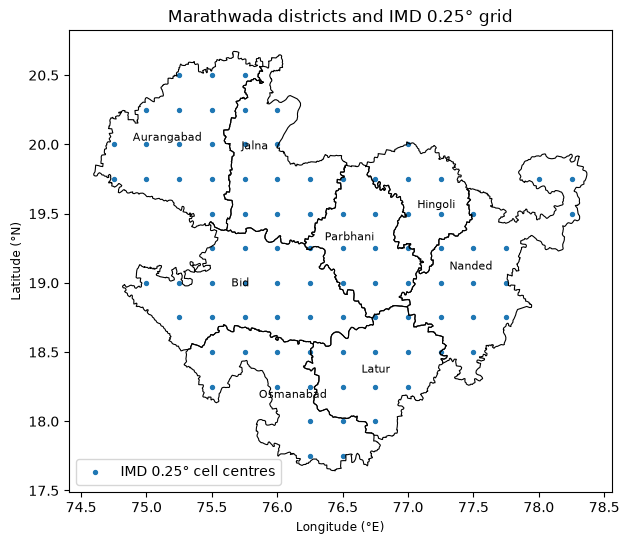

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
md.boundary.plot(ax=ax, color="k", linewidth=0.8)
lon2d, lat2d = np.meshgrid(lon, lat)
ax.scatter(lon2d[inside.values], lat2d[inside.values], s=8, label="IMD 0.25° cell centres")
for _, r in md.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(r["NAME_2"], (p.x, p.y), ha="center", fontsize=8)
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Marathwada districts and IMD 0.25° grid")
ax.legend(loc="lower left")
fig.savefig("../outputs/figures/fig01_study_area.png", dpi=300, bbox_inches="tight")